# Pipeline de streams — las 10 etapas de punta a punta

Proyecto *pipeline-streams-eda* · Estructuras de Datos y Algoritmos (UTEC, 2026-2) · dataset **REES46**

Este cuaderno demuestra el **pipeline completo** procesando un stream de eventos
de comercio electrónico a través de las 10 etapas, cada una con su estructura de
datos propia. Usa el orquestador `src/pipeline.py` que integra el trabajo de los
tres integrantes.

| | Etapa de flujo (por lote) | Estructura |
|---|---|---|
| 0 | Ingesta y buffer | cola FIFO / buffer circular |
| 1 | Preprocesamiento | merge sort + búsqueda binaria |
| 6 | Fraude | filtro de Bloom + Count-Min Sketch |
| 2 | Prioridad | min-heap |
| 3 | Lookup y caché | tabla hash + LRU + matriz dispersa |
| 4 | Índice | B+Tree |
| 8 | Grafo de co-compra | grafo + PageRank + Louvain |

| | Etapa sobre el catálogo (al cerrar) | Estructura |
|---|---|---|
| 5 | Índice multidimensional | k-d tree + k-NN |
| 7 | Similitud aproximada | IVF + MinHash LSH |
| 9 | Servicio | trie + top-k |

El orden de flujo es `0 → 1 → 6 → 2 → 3 → 4 → 8` (la etapa 6 va antes de la
prioridad para que la 2 priorice con su decisión de fraude), y al cerrar el
stream se arman las etapas 5, 7 y 9 sobre todo el catálogo.

In [1]:
import sys, os

RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if RAIZ not in sys.path:
    sys.path.insert(0, RAIZ)

import matplotlib.pyplot as plt

from experimentos.datos_sinteticos import generar_eventos_fraude
from src.pipeline import Pipeline, ETAPAS, ORDEN_FLUJO, ORDEN_CIERRE

print("Entorno listo. Raíz:", RAIZ)

Entorno listo. Raíz: C:\Users\User\Axel\Maestria_Ciencia_Datos\CICLO 2\Estrucutura de datos\pipeline-streams-eda


## 1. Correr el pipeline completo

Generamos un stream sintético de 10 000 eventos con patrones de fraude (campos
`ip`, `dispositivo_id`, `medio_pago` y la etiqueta `es_fraude`, que solo sirve
para medir). El orquestador lo procesa lote por lote y luego **cierra** el stream
para armar las etapas sobre el catálogo.

In [2]:
eventos, lista_negra = generar_eventos_fraude(10_000, semilla=42)
print(f"Stream: {len(eventos)} eventos  |  lista negra: {len(lista_negra)} identificadores")

pipe = Pipeline(lista_negra=lista_negra, semilla=42)
pipe.procesar(eventos).cerrar()
print("Pipeline procesado y cerrado.")

Stream: 10000 eventos  |  lista negra: 24 identificadores


Pipeline procesado y cerrado.


## 2. Qué pasó en cada etapa

`resumen()` devuelve las métricas de las 10 etapas en el orden del pipeline.

In [3]:
resumen = pipe.resumen()

def fmt(v):
    if isinstance(v, float):
        return f"{v:.3f}"
    if isinstance(v, dict):
        return ", ".join(f"{k}={fmt(x)}" for k, x in v.items())
    return str(v)

print(f"{'#':>2}  {'Etapa':<42} {'Tiempo':>8}   Métricas")
print("-" * 100)
for etapa in ORDEN_FLUJO + ORDEN_CIERRE:
    t = "(en la 9)" if etapa == 7 else f"{pipe.tiempos[etapa]:.3f}s"
    print(f"{etapa:>2}  {ETAPAS[etapa]:<42} {t:>8}   {fmt(resumen[etapa])}")

 #  Etapa                                        Tiempo   Métricas
----------------------------------------------------------------------------------------------------
 0  Ingesta y buffer                             0.006s   lotes=10, eventos_recibidos=10000
 1  Preprocesamiento por lotes                   0.052s   validos=10000, descartados=0, duplicados=0
 6  Filtrado probabilístico (fraude)             0.204s   marcados=1652, precision=1.000, recall=0.948
 2  Cola con prioridades                         0.094s   fraude_o_pago=1652, express=0, estandar=226, baja=8122
 3  Lookup y caché                               0.028s   productos=500, cache_tasa_aciertos=0.000, matriz_celdas=9688
 4  Índice principal (B+Tree)                    0.022s   eventos_indexados=10000, altura_tiempo=2, altura_precio=2
 8  Grafo de co-compra                           0.001s   compras=275, productos=205, aristas=33
 5  Índice multidimensional (KD-Tree)            0.018s   productos_indexados=500
 7  Simil

### Tiempo por etapa

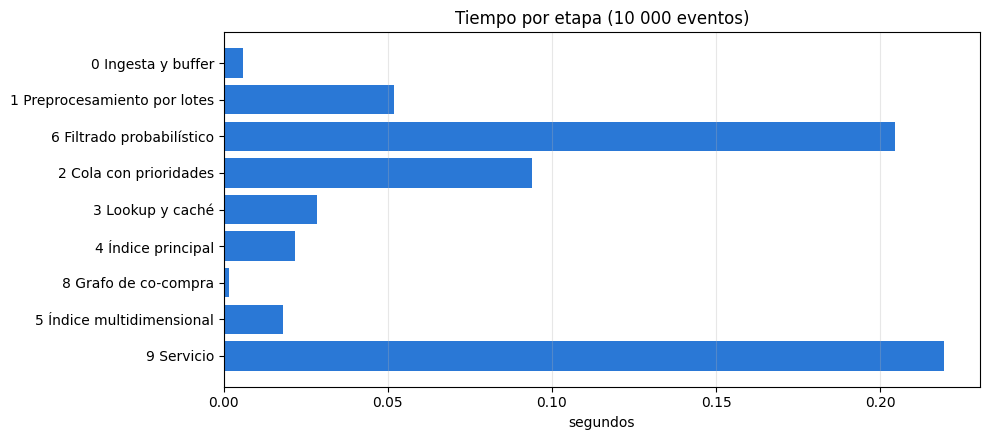

In [4]:
etapas = [e for e in ORDEN_FLUJO + ORDEN_CIERRE if e != 7]  # la 7 va sumada en la 9
tiempos = [pipe.tiempos[e] for e in etapas]
etiquetas = [f"{e} {ETAPAS[e].split('(')[0].strip()}" for e in etapas]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(etiquetas, tiempos, color="#2a78d6")
ax.invert_yaxis()
ax.set_xlabel("segundos")
ax.set_title("Tiempo por etapa (10 000 eventos)")
ax.grid(True, axis="x", alpha=.3)
plt.tight_layout(); plt.show()

## 3. Detección de fraude (etapa 6)

La etapa 6 anota cada evento y la etapa 2 hace que lo marcado como fraude salga
primero. Medimos su calidad contra la etiqueta `es_fraude`.

In [5]:
m6 = resumen[6]
print(f"Eventos marcados como fraude: {m6['marcados']}")
print(f"Precisión: {m6['precision']:.3f}   Recall: {m6['recall']:.3f}")
print("\nAlertas más urgentes (orden de prioridad):")
for a in pipe.servicio.alertas[:6]:
    print(f"  {a['event_type']:<9} producto {a['product_id']}  usuario {a['user_id']}  "
          f"score {a['score']}  ({a['motivos']})")

Eventos marcados como fraude: 1652
Precisión: 1.000   Recall: 0.948

Alertas más urgentes (orden de prioridad):
  view      producto 1000307  usuario 507339571  score 0.625  (lista_negra)
  view      producto 1000083  usuario 508944387  score 0.65  (lista_negra)
  view      producto 1000136  usuario 501829622  score 0.675  (lista_negra)
  view      producto 1000052  usuario 504276341  score 0.7  (lista_negra)
  view      producto 1000489  usuario 500314430  score 0.725  (lista_negra)
  view      producto 1000197  usuario 503909069  score 0.75  (lista_negra)


## 4. Recomendaciones e influencia (etapas 8 y 9)

El grafo de co-compra (8) da los productos más influyentes por PageRank, y el
servicio (9) recomienda productos similares y autocompleta marcas/categorías.

In [6]:
print("Productos más influyentes (PageRank):")
for producto, puntaje in pipe.influyentes(5):
    print(f"  producto {producto}  ->  {puntaje:.6f}")

demo = pipe.evento_para_demo()
pid = demo["product_id"]
print(f"\nRecomendaciones para el producto {pid}:")
for p, s in pipe.servicio.recomendar(pid, k=3):
    print(f"  producto {p}  (relevancia {s:.3f})")

print("\nAutocompletar 'sa':", pipe.servicio.autocompletar("sa", k=5))

Productos más influyentes (PageRank):
  producto 1000176  ->  0.018928
  producto 1000096  ->  0.018832
  producto 1000064  ->  0.015867
  producto 1000496  ->  0.015867
  producto 1000236  ->  0.015423

Recomendaciones para el producto 1000186:
  producto 1000220  (relevancia 0.956)
  producto 1000332  (relevancia 0.943)
  producto 1000461  (relevancia 0.941)

Autocompletar 'sa': ['samsung']


## 5. El recorrido de un evento por las 10 etapas

La mejor forma de ver el pipeline integrado: tomamos un evento (una compra
marcada como fraude) y mostramos **qué le pasó en cada una de las 10 etapas**.

In [7]:
evento = pipe.evento_para_demo()
print(f"Evento: {evento['event_type']} del producto {evento['product_id']} (usuario {evento['user_id']})\n")
for etapa, nombre, resultado in pipe.recorrido(evento):
    print(f"  {etapa}  {nombre:<42} {resultado}")

Evento: purchase del producto 1000186 (usuario 502488628)

  0  Ingesta y buffer                           entró por la cola FIFO en uno de los 10 lotes
  1  Preprocesamiento por lotes                 válido y sin duplicar; event_time normalizado a 1569888159
  6  Filtrado probabilístico (fraude)           marcado como fraude (score 0.85, motivos: velocidad)
  2  Cola con prioridades                       prioridad 0 (fraude_o_pago)
  3  Lookup y caché                             ficha del producto 1000186: 15 vistas, 1 carritos, 1 compras, categoría desconocido
  4  Índice principal (B+Tree)                  precio vigente 1008.04; 16 eventos en el mismo segundo
  8  Grafo de co-compra                         puesto 56 de 205 en PageRank; comprado junto con ningún otro todavía
  5  Índice multidimensional (KD-Tree)          vecinos más cercanos en el KD-Tree: [1000220, 1000332, 1000461]
  7  Similitud aproximada (IVF y MinHash + LSH) recomendados por IVF: [1000220, 1000332, 1000461]; 

## 6. El porqué de las estructuras: memoria

Cada etapa usa una estructura propia porque gana en complejidad o en memoria
frente a la solución ingenua. Como ejemplo, las dos estructuras probabilísticas
de la etapa 6 (fraude) frente a sus equivalentes exactos de Python.

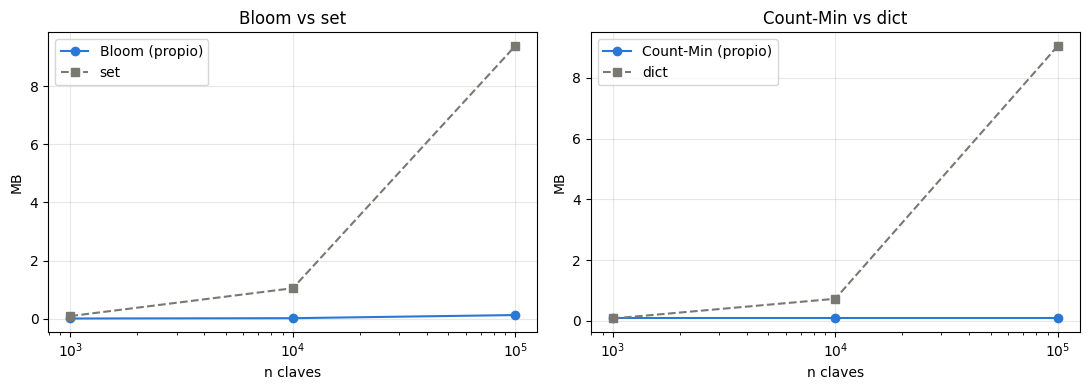

A 100K claves:  Bloom 0.12 MB vs set 9.39 MB  |  Count-Min 0.11 MB (fija) vs dict 9.04 MB


In [8]:
import sys
from src.etapa6_probabilistico import FiltroBloom, CountMinSketch

tamanos = [1_000, 10_000, 100_000]
bloom_mb, set_mb, cm_mb, dict_mb = [], [], [], []
for n in tamanos:
    claves = [f"ip:{i:08x}" for i in range(n)]
    b = FiltroBloom(n_esperado=n, prob_fp=0.01); b.actualizar(claves)
    bloom_mb.append(b.memoria_bytes / 1e6)
    s = set(claves); set_mb.append((sys.getsizeof(s) + sum(sys.getsizeof(k) for k in claves)) / 1e6)
    c = CountMinSketch(epsilon=0.001, delta=0.01)
    for k in claves: c.sumar(k)
    cm_mb.append(c.memoria_bytes / 1e6)
    d = {k: 1 for k in claves}; dict_mb.append((sys.getsizeof(d) + sum(sys.getsizeof(k) for k in d)) / 1e6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(tamanos, bloom_mb, "o-", color="#2a78d6", label="Bloom (propio)")
ax1.plot(tamanos, set_mb, "s--", color="#7a7873", label="set")
ax1.set_title("Bloom vs set"); ax1.set_xscale("log"); ax1.set_xlabel("n claves"); ax1.set_ylabel("MB"); ax1.legend(); ax1.grid(True, alpha=.3)
ax2.plot(tamanos, cm_mb, "o-", color="#2a78d6", label="Count-Min (propio)")
ax2.plot(tamanos, dict_mb, "s--", color="#7a7873", label="dict")
ax2.set_title("Count-Min vs dict"); ax2.set_xscale("log"); ax2.set_xlabel("n claves"); ax2.set_ylabel("MB"); ax2.legend(); ax2.grid(True, alpha=.3)
plt.tight_layout(); plt.show()
print(f"A 100K claves:  Bloom {bloom_mb[-1]:.2f} MB vs set {set_mb[-1]:.2f} MB  |  Count-Min {cm_mb[-1]:.2f} MB (fija) vs dict {dict_mb[-1]:.2f} MB")

## Conclusiones

- El pipeline procesa el stream de punta a punta en **10 etapas**, cada una con la
  estructura adecuada: cola FIFO, merge sort, Bloom + Count-Min, heap, tabla hash,
  B+Tree, grafo con PageRank, k-d tree, IVF + MinHash LSH y trie.
- La **detección de fraude** (etapa 6) marca los eventos sospechosos con precisión
  ≈ 1,0 y recall ≈ 0,95, y la prioridad (etapa 2) los atiende primero.
- El **servicio** (etapa 9) entrega recomendaciones, autocompletado, influencia y
  alertas sobre el catálogo completo.
- El hilo común es el de estructuras de datos: elegir *dónde vive cada dato* para
  ganar en complejidad y memoria, que es lo que permite escalar a millones de
  eventos.